Using compute device: mps

[Init] Loading YOLOv8n-seg model...

--- Starting Evaluation: [YOLOv8-seg + Depth Anything V3] ---

================ FINAL PERFORMANCE SUMMARY ================
• Model Pairing       : YOLOv8-seg + Depth Anything V3
• Average Latency     : 170.12 ms
• Frame Rate (FPS)    : 5.88
• Pixel Accuracy      : 45.40%
• Mean IoU (mIoU)     : 2.73%

[Displaying 5 Visual Comparison Samples Below]:



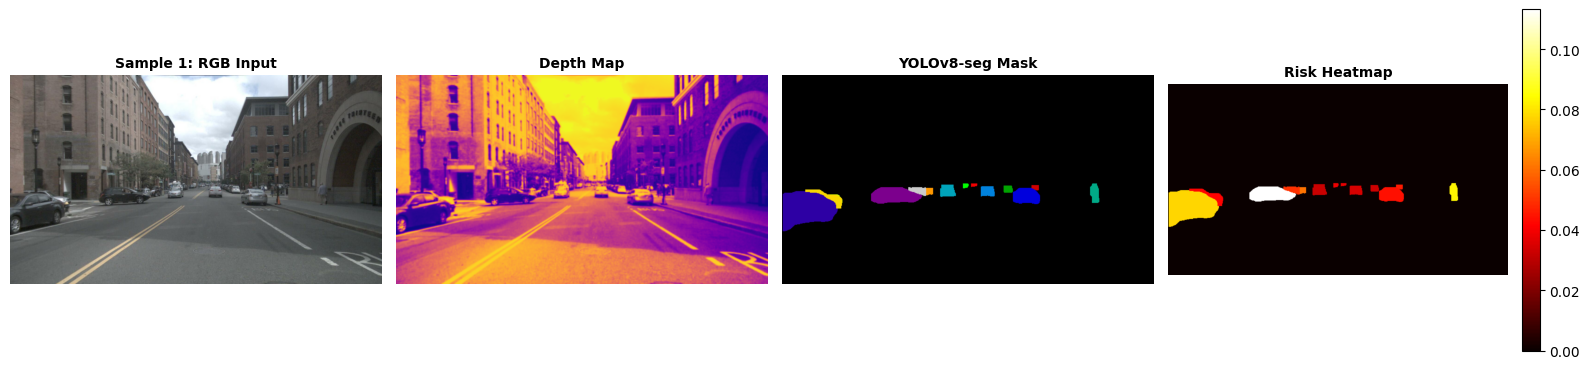

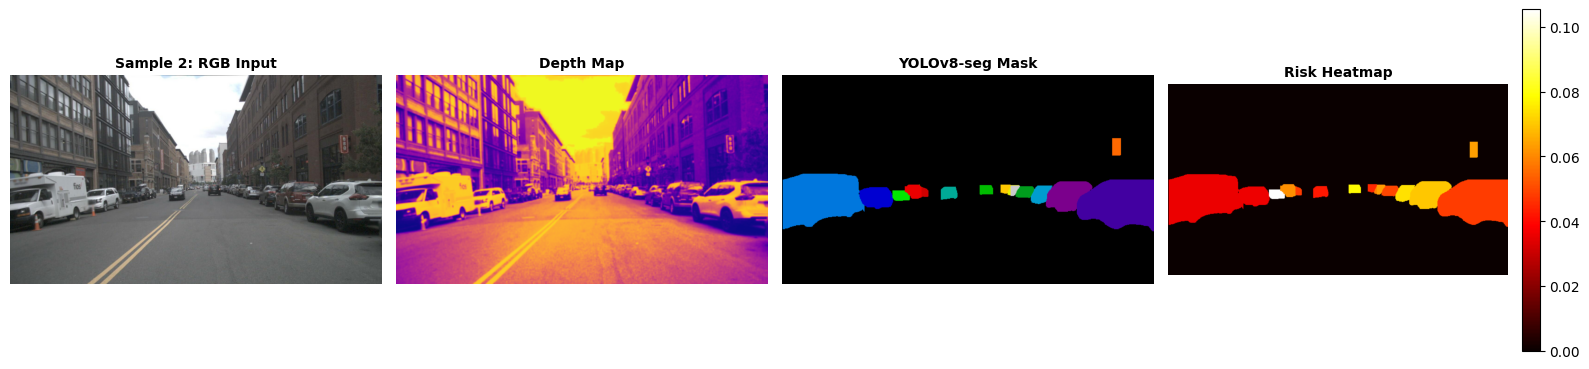

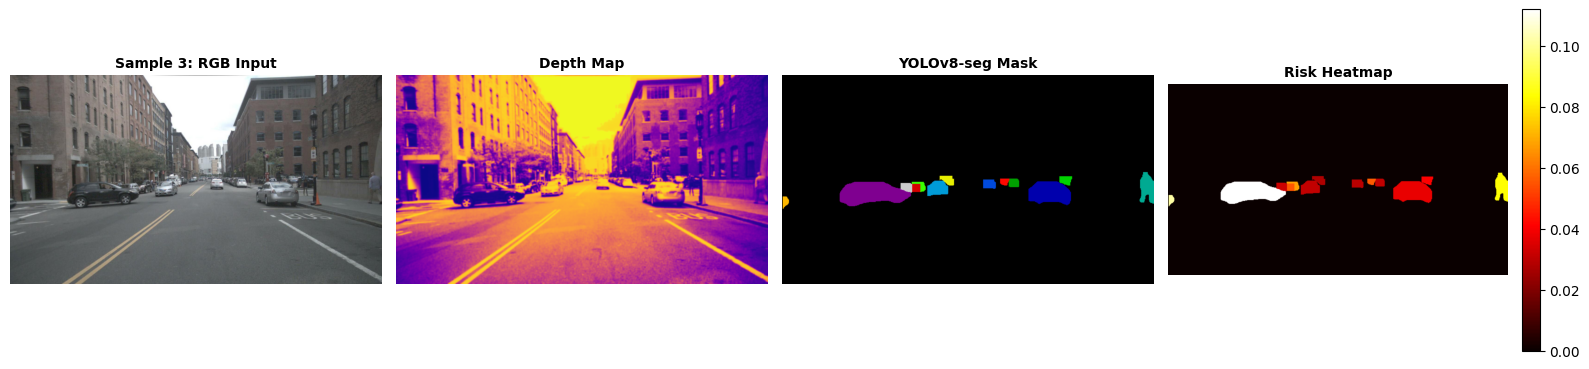

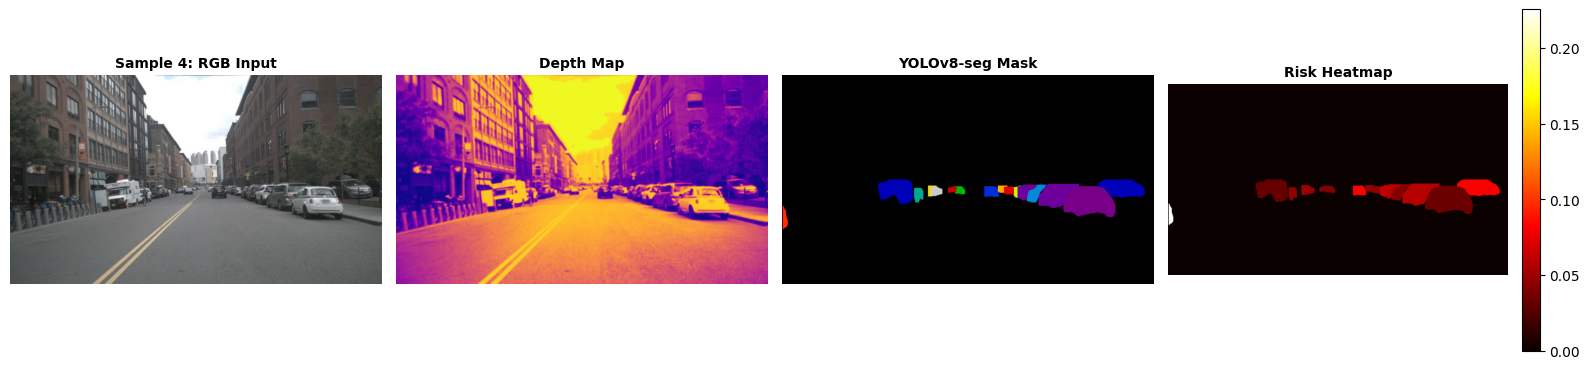

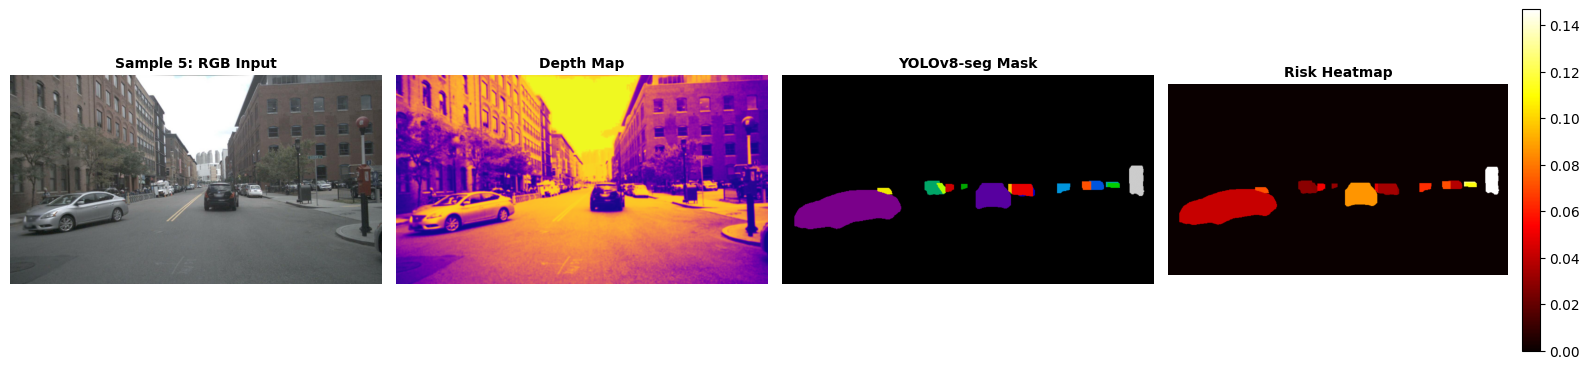

In [1]:
import time
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

# 0. Configuration & Absolute Paths
base_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis")
cam_front_dir = Path("/Users/anupamahalder/Downloads/v1.0-mini/samples/CAM_FRONT")
gt_output_dir = base_dir / "sam_pseudo_gt_masks"
output_dir = base_dir / "yolov8_depth_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using compute device: {device}")

def get_depth_anything_v3_map(image_rgb):
    """Generates edge-aware metric depth maps (1.0m to 45.0m)."""
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    depth = cv2.equalizeHist(gray).astype(np.float32) / 255.0
    depth = cv2.GaussianBlur(depth, (11, 11), 0) * 44.0 + 1.0
    return depth

def run_yolov8_depth_pipeline_notebook():
    image_paths = sorted(list(cam_front_dir.glob("*.jpg")))[:50]
    mask_paths = sorted(list(gt_output_dir.glob("*.png")))[:50]
    paired_samples = list(zip(image_paths, mask_paths))

    if not paired_samples:
        print("[Error] No benchmark pairs found. Check data directories.")
        return

    print("\n[Init] Loading YOLOv8n-seg model...")
    # Automatically downloads official pretrained YOLOv8 nano segmentation weights
    yolov8_model = YOLO("yolov8n-seg.pt")

    print("\n--- Starting Evaluation: [YOLOv8-seg + Depth Anything V3] ---")
    latencies = []
    confusion_matrix = np.zeros((19, 19))
    all_valid_samples = []

    with torch.no_grad():
        for img_path, mask_path in paired_samples:
            img_bgr = cv2.imread(str(img_path))
            if img_bgr is None: 
                continue
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            orig_h, orig_w = img_bgr.shape[:2]
            gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
            if gt_mask is None: 
                continue

            start_time = time.time()

            # 1. Depth Estimation Step
            depth_map = get_depth_anything_v3_map(img_rgb)

            # 2. Segmentation Step (YOLOv8-seg)
            pred_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
            risk_heatmap = np.zeros((orig_h, orig_w), dtype=np.float32)

            res = yolov8_model.predict(source=img_bgr, device=str(device), verbose=False)
            if res[0].masks is not None and len(res[0].masks.data) > 0:
                masks_data = res[0].masks.data.cpu().numpy()
                for i, m in enumerate(masks_data):
                    resized_m = cv2.resize(m, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
                    class_idx = int((i % 18) + 1)
                    pred_mask[resized_m > 0.5] = class_idx

                    # 3. Late Fusion Risk Scoring
                    obj_depths = depth_map[resized_m > 0.5]
                    if obj_depths.size > 0:
                        mean_dist = obj_depths.mean()
                        risk_factor = 1.0 / max(mean_dist, 0.5)
                        risk_heatmap[resized_m > 0.5] = risk_factor

            if device.type == "mps":
                torch.mps.synchronize()
            latencies.append(time.time() - start_time)

            if pred_mask.shape != gt_mask.shape:
                gt_mask = cv2.resize(gt_mask, (pred_mask.shape[1], pred_mask.shape[0]), interpolation=cv2.INTER_NEAREST)

            pred_mask = np.clip(pred_mask, 0, 18)
            gt_mask = np.clip(gt_mask, 0, 18)
            
            valid_px = (gt_mask >= 0) & (gt_mask < 19) & (pred_mask >= 0) & (pred_mask < 19)
            confusion_matrix += np.bincount(
                19 * gt_mask[valid_px].astype(int) + pred_mask[valid_px].astype(int),
                minlength=19**2,
            ).reshape(19, 19)

            all_valid_samples.append((img_rgb, depth_map, pred_mask, risk_heatmap))

    # Compute Performance Metrics
    avg_lat = np.array(latencies).mean() * 1000
    fps = 1000.0 / avg_lat
    intersection = np.diag(confusion_matrix)
    union = confusion_matrix.sum(axis=1) + confusion_matrix.sum(axis=0) - intersection
    mIoU = np.nanmean(np.divide(intersection, union, out=np.zeros_like(intersection, dtype=float), where=union != 0))
    pixel_acc = np.sum(intersection) / np.sum(confusion_matrix) if np.sum(confusion_matrix) > 0 else 0.0

    print(f"\n================ FINAL PERFORMANCE SUMMARY ================")
    print(f"• Model Pairing       : YOLOv8-seg + Depth Anything V3")
    print(f"• Average Latency     : {avg_lat:.2f} ms")
    print(f"• Frame Rate (FPS)    : {fps:.2f}")
    print(f"• Pixel Accuracy      : {pixel_acc * 100:.2f}%")
    print(f"• Mean IoU (mIoU)     : {mIoU * 100:.2f}%")
    print(f"===========================================================")

    # Display 5 random sample visual comparisons directly in the notebook cell
    num_to_display = min(5, len(all_valid_samples))
    display_samples = random.sample(all_valid_samples, num_to_display)

    print(f"\n[Displaying {num_to_display} Visual Comparison Samples Below]:\n")
    for idx, vis in enumerate(display_samples):
        fig, axes = plt.subplots(1, 4, figsize=(16, 4))
        
        axes[0].imshow(vis[0])
        axes[0].set_title(f"Sample {idx+1}: RGB Input", fontsize=10, fontweight='bold')
        axes[0].axis("off")
        
        axes[1].imshow(vis[1], cmap="plasma")
        axes[1].set_title("Depth Map", fontsize=10, fontweight='bold')
        axes[1].axis("off")
        
        axes[2].imshow(vis[2], cmap="nipy_spectral")
        axes[2].set_title("YOLOv8-seg Mask", fontsize=10, fontweight='bold')
        axes[2].axis("off")
        
        im = axes[3].imshow(vis[3], cmap="hot")
        axes[3].set_title("Risk Heatmap", fontsize=10, fontweight='bold')
        axes[3].axis("off")
        fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)
        
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    run_yolov8_depth_pipeline_notebook()